# CAT 2: Image Classification with PyTorch
## Final report and submission notebook

| | |
|---|---|
| **Course** | DSA 4050-XA: Deep Learning, USIU-Africa (Fall 2026) |
| **Lecturer** | Dr. Alex Wambua |
| **Student** | Selmah Tzindori (669602) |
| **Notebook** | `05_submission_and_report.ipynb` |
| **Code** | Full pipeline in notebooks `00`–`04` and `src/cat2_utils.py` (GitHub: https://github.com/SelmahT/cifar10-image-classification) |

---
### Summary
The task is to classify **32×32 colour images into 10 classes** (airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck), training on only **4,000 labelled images** and predicting **46,000 unlabelled** ones.

The final model is an **ensemble of 10 fine-tuned, ImageNet-pretrained networks** (5 × Vision Transformer ViT-Small + 5 × ConvNeXt-Tiny, one per cross-validation fold). Images are upscaled to 224×224 and predicted with test-time augmentation. Hyper-parameters were chosen by **Bayesian optimisation (Optuna TPE) with median pruning**.

| Model | Accuracy | How measured |
|---|---|---|
| Random guessing | 10.0% | 10 balanced classes |
| CNN trained from scratch (baseline) | 81.1% | validation fold 0 |
| ViT-Small pretrained, default settings | 96.4% | validation fold 0 |
| ViT-Small, Optuna-tuned | 97.6% | **5-fold out-of-fold** |
| ConvNeXt-Tiny, same settings | 97.5% | **5-fold out-of-fold** |
| **Final ensemble (ViT + ConvNeXt)** | **98.05%** | **5-fold out-of-fold (4,000 images)** |

**Expected test accuracy: about 98%.** The prediction file is `Test_predictions.csv` (same format as `Test.csv`, with the `label` column filled).

### How the CAT requirements are met
| Requirement | Where | Section |
|---|---|---|
| 1. Data loader subclassing `torch.utils.data.Dataset` | `CIFARCSVDataset` | §2 |
| 2. Data augmentation for the training data | crop, flip, RandAugment, random erasing | §3 |
| 3. Appropriate algorithm for hyper-parameter selection | Optuna TPE (Bayesian optimisation) + median pruning | §5 |
| 4. Accuracy | 5-fold cross-validated ensemble, 98.05% | §6–§7 |
| Deliverable: CSV like `Test.csv` with labels | `Test_predictions.csv`, verified | §8 |

*This notebook runs on CPU in about 2 minutes: it loads the saved results of notebooks 01–04 and re-checks the submission file.*

## 0 · Setup

In [1]:
from google.colab import drive
drive.mount("/content/drive")

import sys
sys.path.insert(0, "/content/drive/MyDrive/DSA4050/cat2-image-classification/src")
import importlib
import cat2_utils as cu
importlib.reload(cu)
cu.set_seed()
NOTEBOOK = "05_submission_and_report"
PATHS = cu.PATHS

Mounted at /content/drive
Random seed set to 42


In [2]:
import os, json, inspect, glob
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
pd.set_option("display.width", 160)

DATA_SOURCE = "/content/drive/MyDrive/Advanced ML"      # the lecturer's shared folder (shortcut)
DATA_DIR = Path(cu.restore_data(DATA_SOURCE))
RESULTS = cu.load_results()


def show(name, width=900):
    """Display a figure saved by an earlier notebook."""
    p = os.path.join(PATHS["figures"], f"{name}.png")
    display(Image(p, width=width)) if os.path.exists(p) else print(f"(figure {name} not found)")


def table(name):
    p = os.path.join(PATHS["tables"], f"{name}.csv")
    if os.path.exists(p):
        return pd.read_csv(p)
    print(f"(table {name} not found)"); return pd.DataFrame()

Source folder: /content/drive/MyDrive/Advanced ML
Unzipped 50,000 images to /content/cat2_data/train


## 1 · Problem and data (notebook 01)
- **50,000 images, 32×32 pixels, RGB.** `Train.csv` gives labels for **4,000** of them (400 per class, perfectly balanced). `Test.csv` lists the **46,000** to predict. All images sit in one folder, `train/<id>.png`.
- **Integrity checks passed:** every id has an image, there are no duplicates, there is no overlap between training and test ids, and the test labels are empty.
- Training and test images have **almost identical colour statistics** (channel means 0.491/0.484/0.448 vs 0.491/0.482/0.446), so the labelled sample represents the test set well.
- **Difficulty:** only 8% of the images are labelled, objects are a few pixels wide, and several classes look alike at this resolution (cat/dog, automobile/truck, deer/horse, bird/airplane).
- **Validation design:** the 4,000 labelled images are split into **5 stratified folds** (800 images, exactly 80 per class each), used consistently by all notebooks.

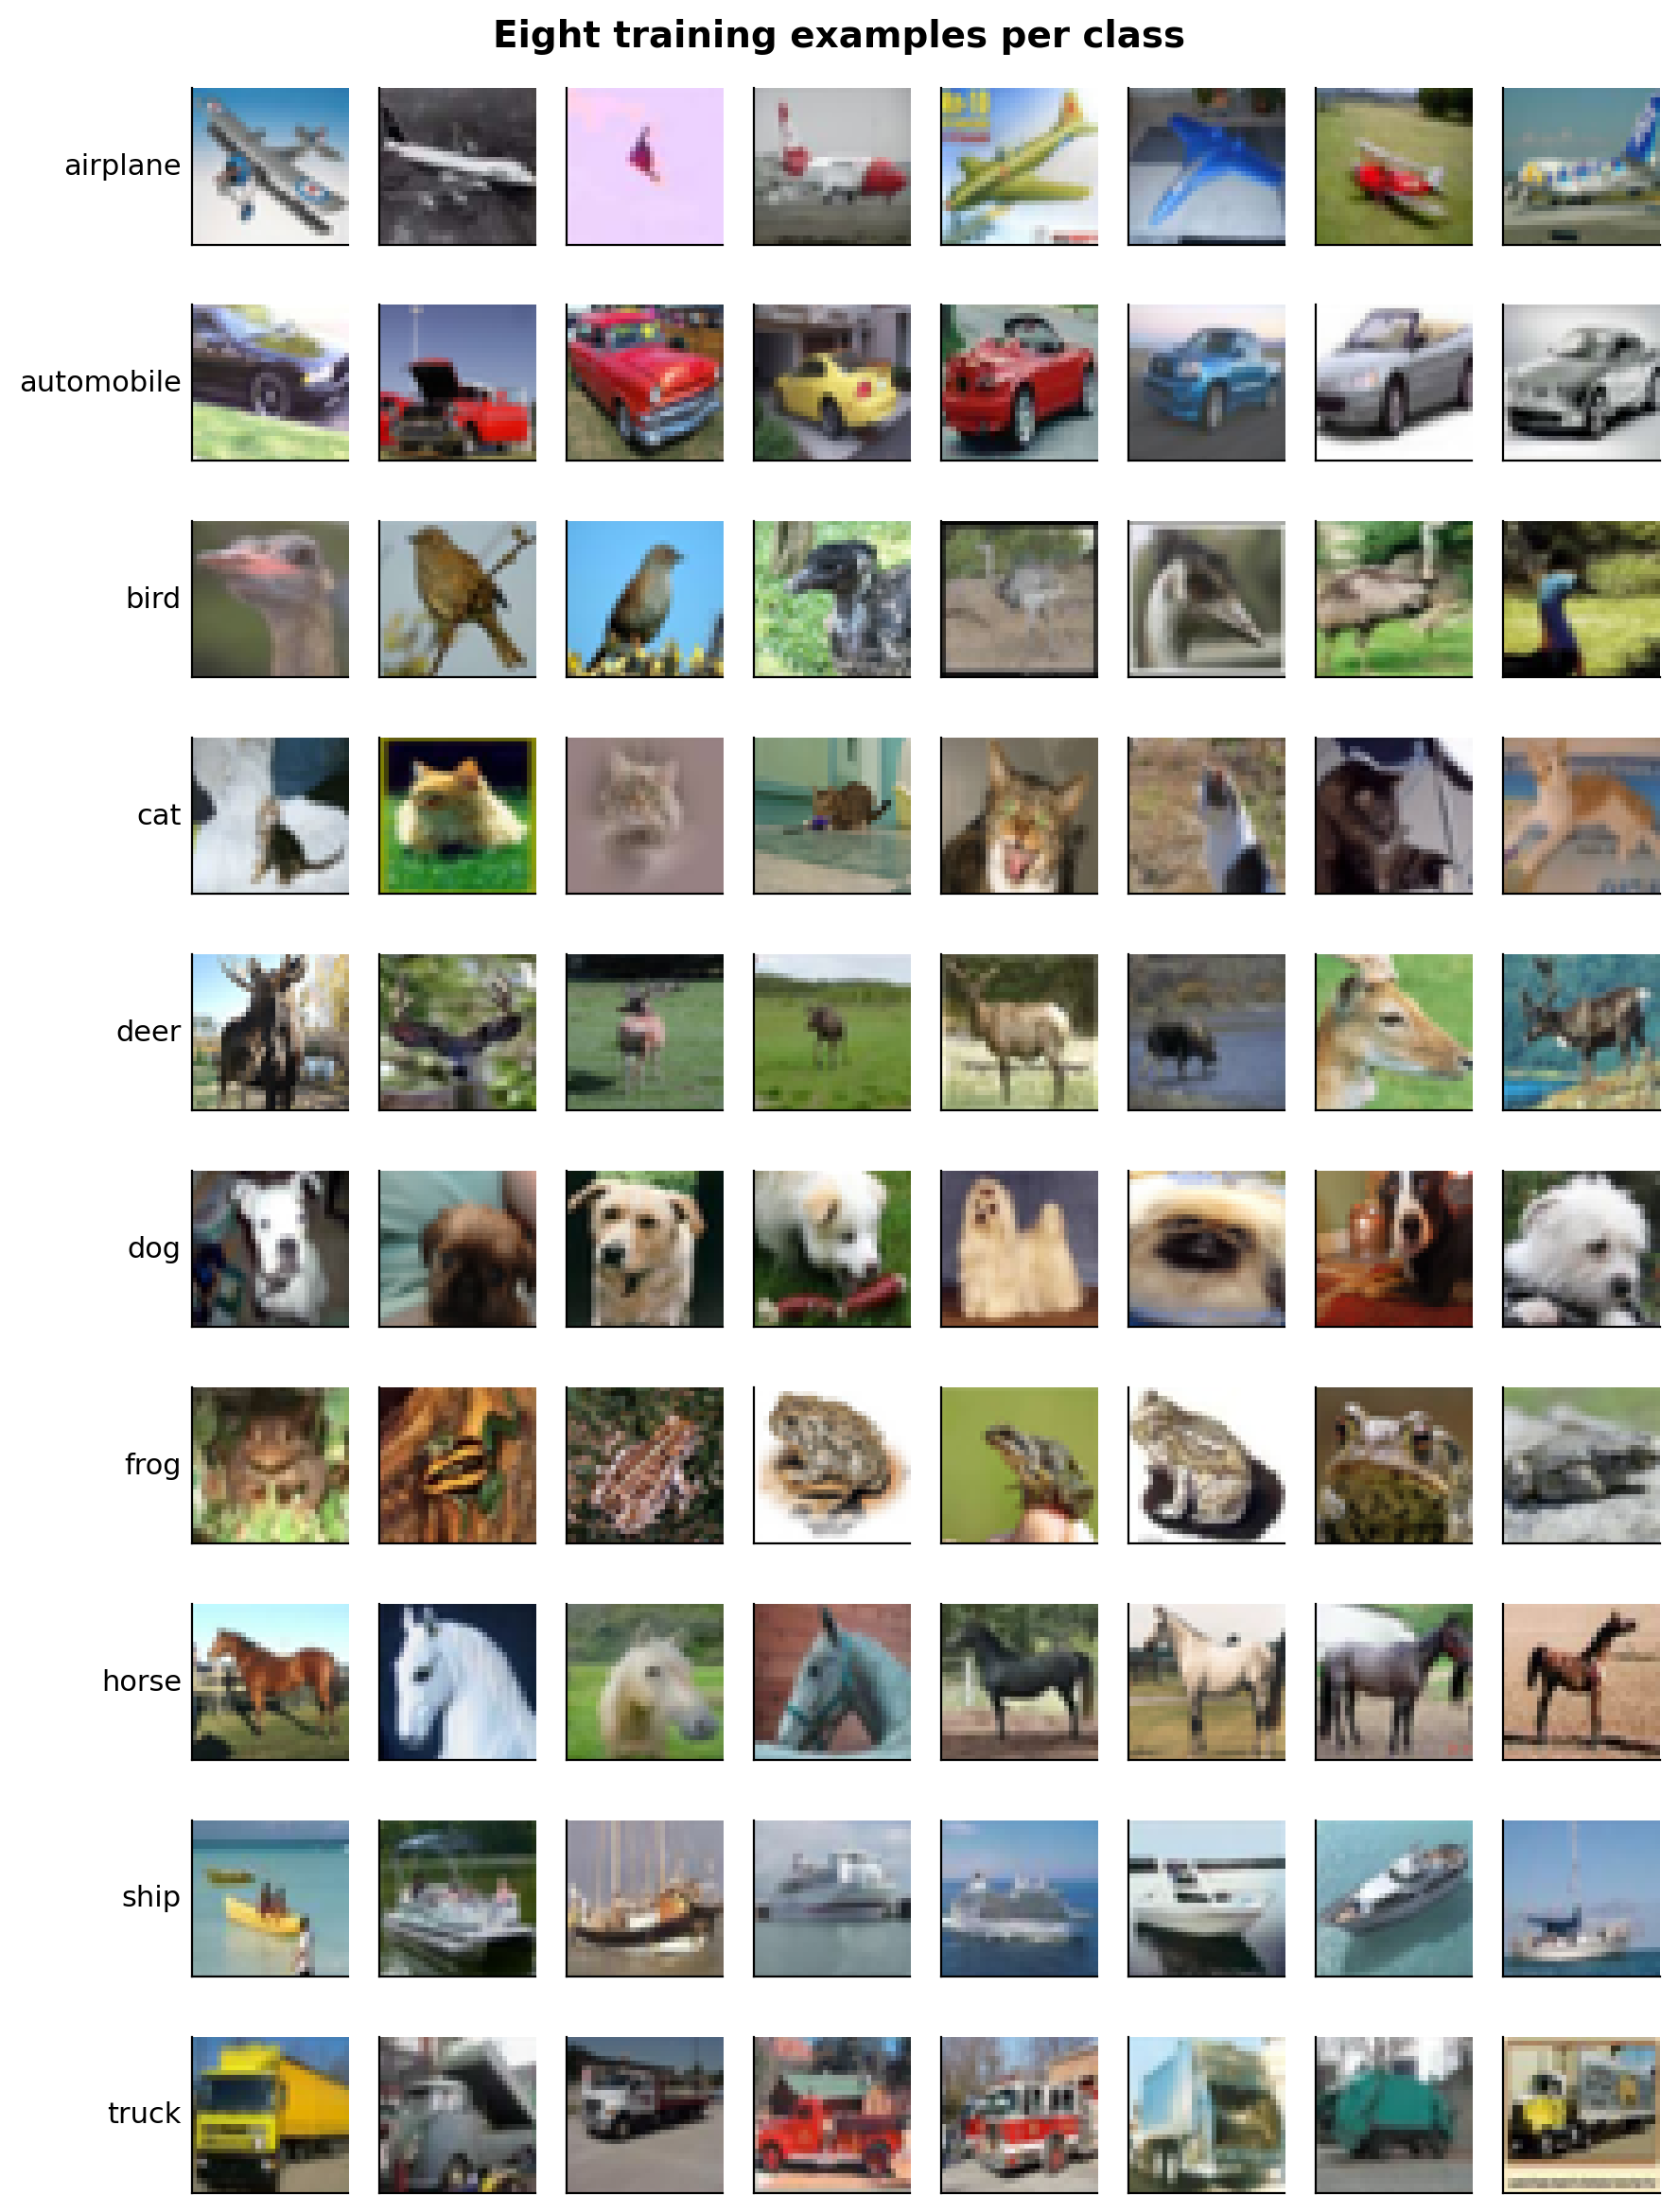

In [3]:
show("01_examples_per_class", 1000)

## 2 · Requirement 1: custom `Dataset` class
`CIFARCSVDataset` subclasses `torch.utils.data.Dataset` and implements the three required methods:

| Method | What it does |
|---|---|
| `__init__(df, image_dir, transform, images)` | Stores the ids and numeric targets from the CSV. Images are read either **from the PNG files** (`image_dir`) or from a **pre-loaded array** (`images`, faster: 4,000 images take 12 MB of memory). |
| `__len__()` | Number of images. |
| `__getitem__(idx)` | Loads image *idx* as a PIL image, applies the `transform` (augmentation + resize + normalisation), and returns `(tensor, target)`. Test images have no label, so the target is **−1**. |

It is wrapped in a `torch.utils.data.DataLoader` for shuffling, batching and parallel loading (2 workers, pinned memory). The cell below prints the class and demonstrates it on the real files.

In [4]:
print(inspect.getsource(cu.CIFARCSVDataset))

    class CIFARCSVDataset(Dataset):
        """
        Custom PyTorch Dataset (subclasses torch.utils.data.Dataset).

        Each item is (image_tensor, label). Images are looked up by their id in a
        DataFrame (Train.csv or Test.csv); test images have no label, so -1 is
        returned instead.

        Parameters
        ----------
        df        : DataFrame with an 'id' column (and 'target' for labelled data)
        image_dir : folder holding <id>.png files
        transform : torchvision transform applied to each PIL image (augmentation
                    for training, plain preprocessing for validation/test)
        images    : optional pre-loaded uint8 array (N, H, W, 3) in the same order
                    as df. The whole dataset is only ~150 MB in memory, so
                    pre-loading avoids re-reading thousands of PNGs every epoch.
        """

        def __init__(self, df: pd.DataFrame, image_dir=None, transform=None, images: np.ndarray = None):
        

In [5]:
train_df, test_df = cu.load_labels(DATA_DIR)
ds = cu.CIFARCSVDataset(train_df, image_dir=DATA_DIR / "train", transform=cu.build_transforms(True, 224))
x, target = ds[0]
print("training set :", len(ds), "images | one item:", tuple(x.shape), x.dtype, "| target", target, f"({cu.CLASSES[target]})")
ds_test = cu.CIFARCSVDataset(test_df, image_dir=DATA_DIR / "train", transform=cu.build_transforms(False, 224))
print("test set     :", len(ds_test), "images | target of a test image:", ds_test[0][1])
xb, yb = next(iter(cu.make_loader(ds, 64, shuffle=True)))
print("DataLoader batch:", tuple(xb.shape), tuple(yb.shape))

training set : 4000 images | one item: (3, 224, 224) torch.float32 | target 9 (truck)
test set     : 46000 images | target of a test image: -1
DataLoader batch: (64, 3, 224, 224) (64,)


## 3 · Requirement 2: data augmentation
With only 400 images per class, the networks would memorise the training images. Augmentation creates a **new random variant of every training image each epoch**. It is applied to training images only; validation and test images are only resized and normalised.

| Step | Effect | Why it is valid here |
|---|---|---|
| `RandomCrop(32, padding=4, reflect)` | Shifts the object by up to 4 px | Objects are not always centred |
| `RandomHorizontalFlip()` | Mirror image | A left-facing horse is still a horse (vertical flips are *not* used: an upside-down ship is unrealistic) |
| `RandAugment(num_ops=2, magnitude=m)` | 2 random operations per image (rotation, shear, colour, contrast, brightness, sharpness, posterize, …) of strength *m* | Lighting, colour and pose vary in real photos; *m* was **tuned by Optuna** (best: 8) |
| `Resize(224, bicubic)` | Upscales to the pretrained networks' resolution | Not augmentation; needed for transfer learning |
| `RandomErasing(p)` | Blanks a random rectangle | Forces the model to use the whole object, not one part (cat ears); *p* was **tuned** (best: 0.21) |

Augmentation is done at 32×32 *before* upscaling, which keeps it fast on Colab's 2 CPU cores.

def build_transforms(train: bool, img_size: int = 32, randaug_magnitude: int = 9,
                     erase_prob: float = 0.25, mean=IMAGENET_MEAN, std=IMAGENET_STD):
    """
    Training (train=True): data augmentation, applied randomly every epoch
        - random crop with 4-px padding (small shifts of the object)
        - horizontal flip (a left-facing horse is still a horse)
        - RandAugment: 2 random photometric/geometric operations of strength
          `randaug_magnitude` (0 = off ... 30 = extreme)
        - resize to img_size (pretrained CNNs work best at larger sizes)
        - random erasing of a patch (forces use of the whole object)
    Evaluation (train=False): only resize + normalise, so results are repeatable.
    """
    from torchvision import transforms as T
    resize = [T.Resize(img_size, interpolation=T.InterpolationMode.BICUBIC, antialias=True)] if img_size != 32 else []
    norm = [T.ToTensor(), T.Normalize(mean, std)]
    if not train:
        return T.C

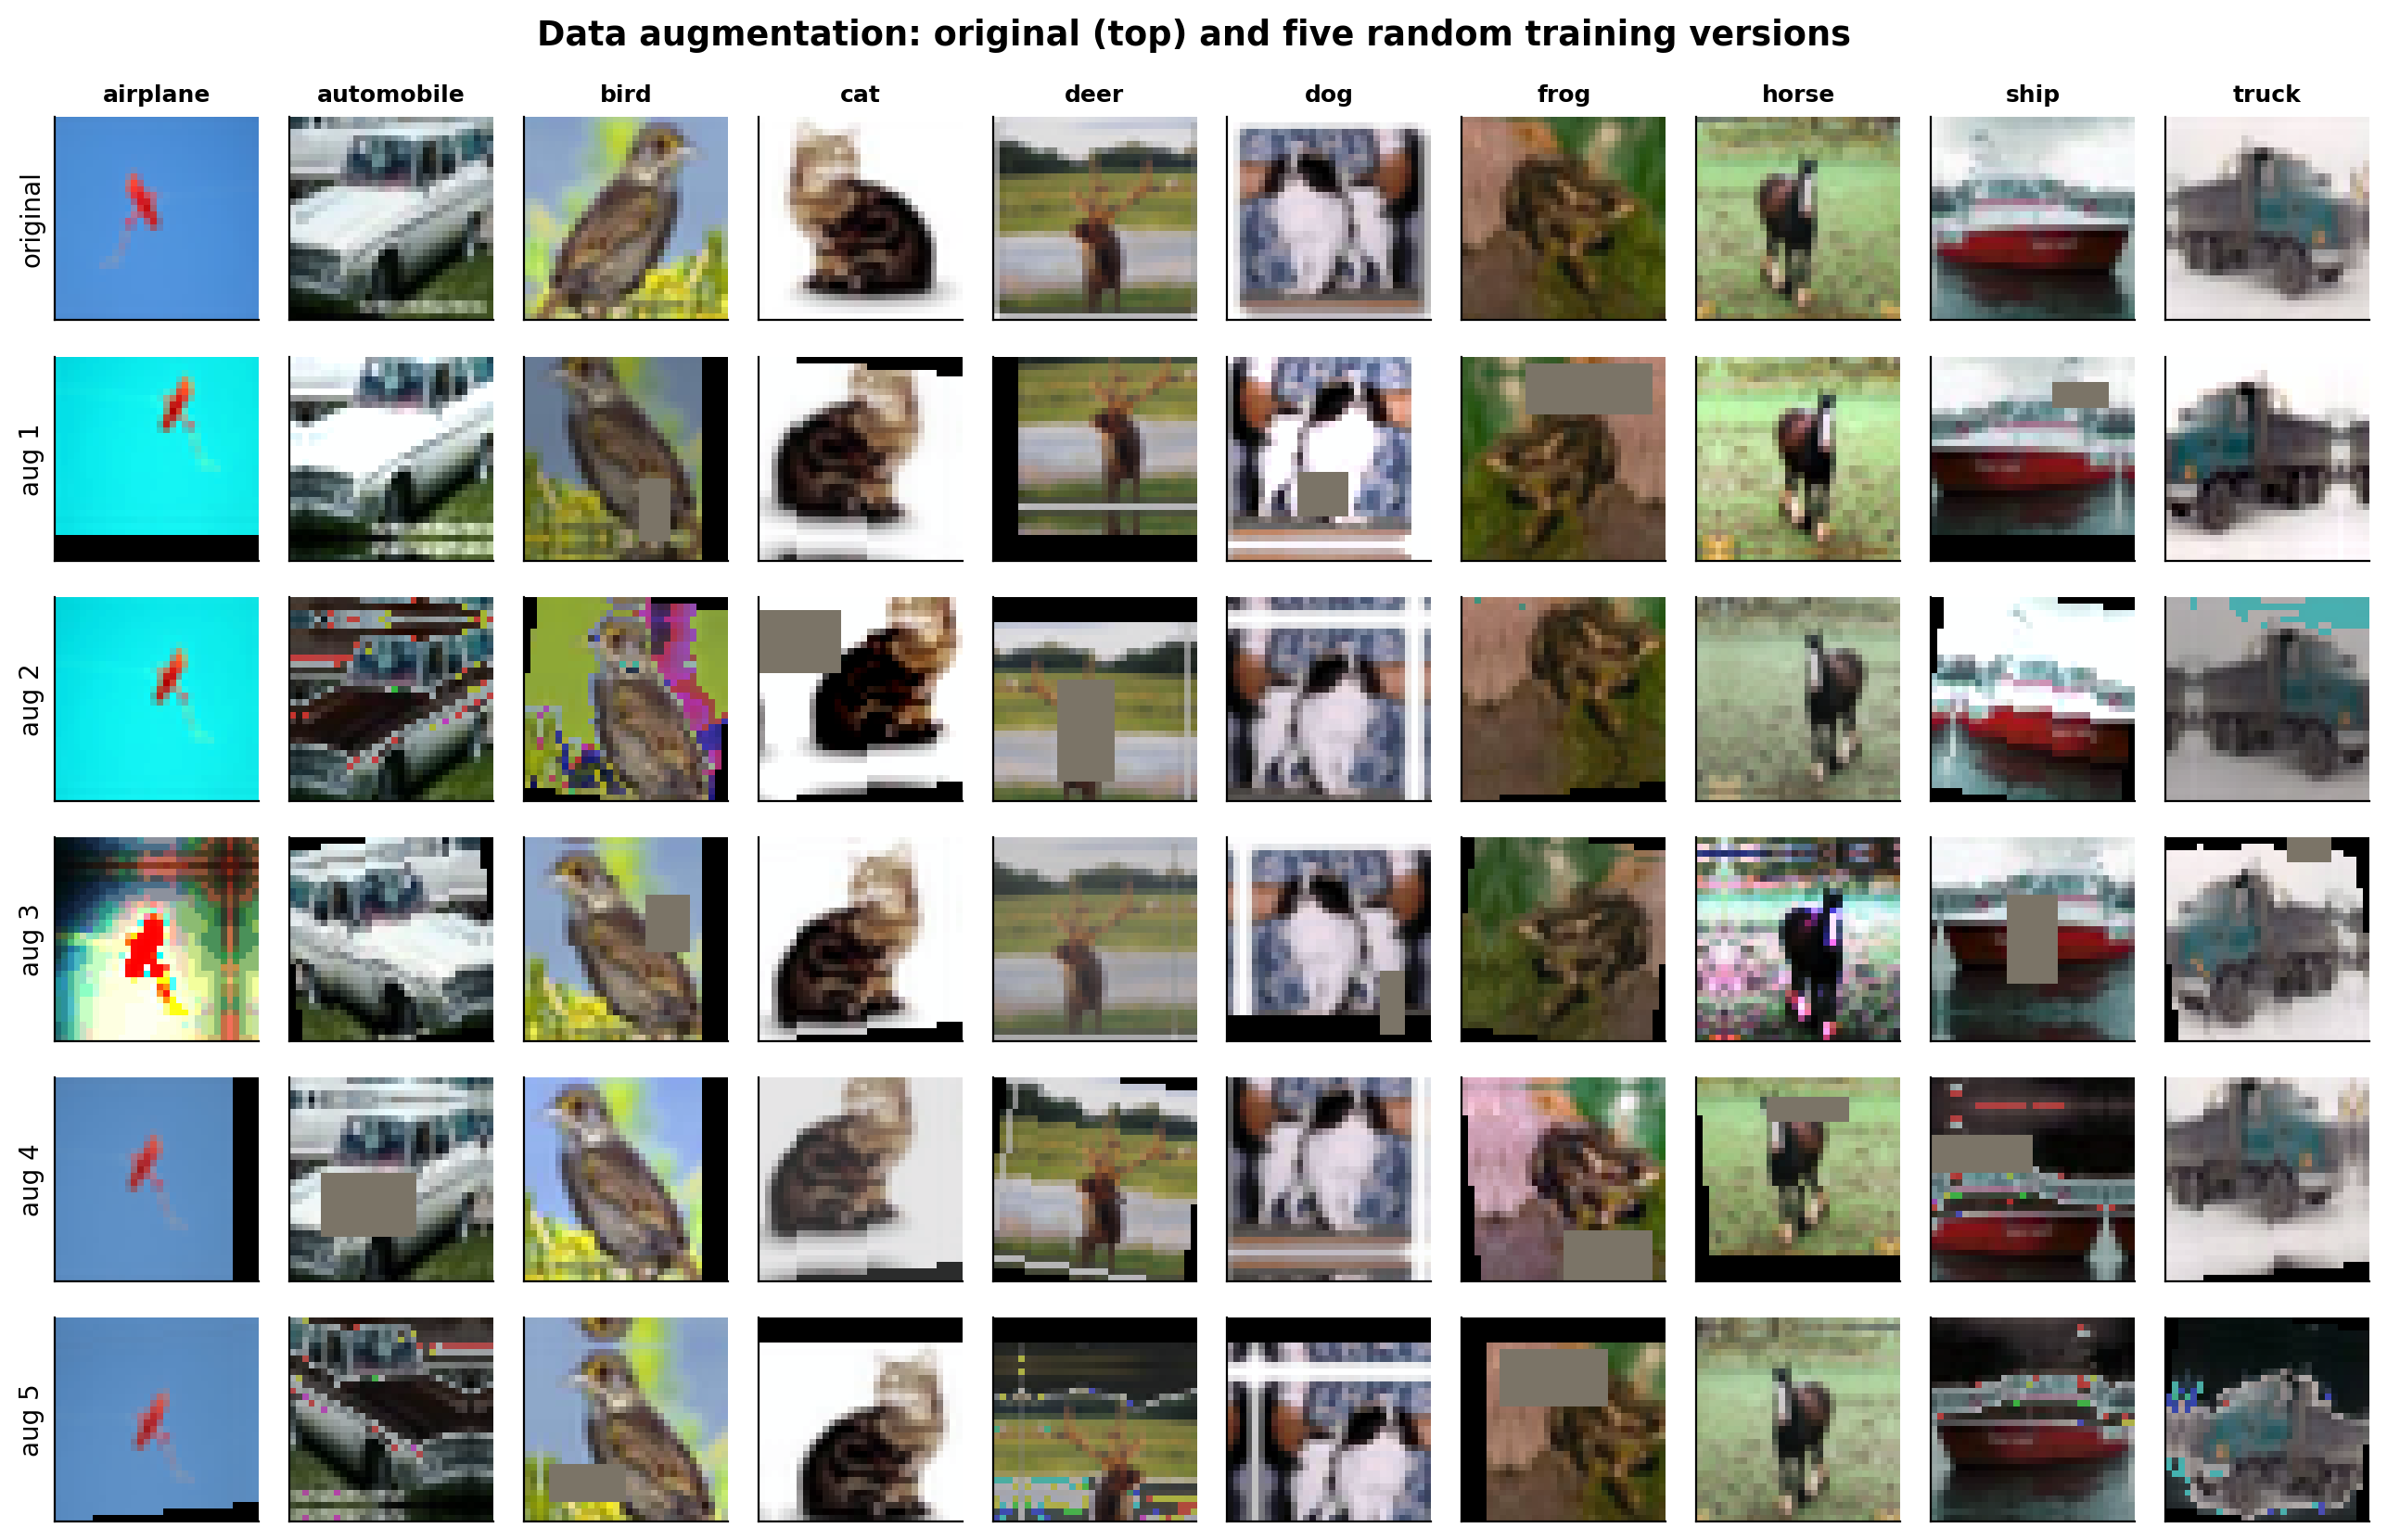

In [6]:
print(inspect.getsource(cu.build_transforms))
show("01_augmentation_examples", 1000)

## 4 · Model development
### 4.1 Baseline: a CNN trained from scratch (notebook 02)
A small **ResNet** (residual blocks 64→128→256 filters, 2.8M parameters) was trained from random weights for 100 epochs (SGD + Nesterov, lr 0.1, cosine schedule, label smoothing 0.1).

**Result: 81.1%** on validation fold 0, with 96% training accuracy, so it clearly **overfits**. The weakest class was cat (60% recall), confused with dog. 3,200 images are too few to learn good visual features from scratch.

### 4.2 Transfer learning: backbone screening (notebook 03)
Networks **pretrained on ImageNet** already contain general visual features (edges, textures, object parts). Only a **new 10-class output layer** is added, and the whole network is **fine-tuned** with a small learning rate. The 32×32 images are upscaled to **224×224**, the resolution the networks were trained at.

Three architectures were fine-tuned with identical default settings (8 epochs, AdamW lr 1e-4):

,backbone,val_acc,best_epoch,params_millions,minutes
0,vit_small_patch16_224.augreg_in21k_ft_in1k,0.96375,6.0,21.7,1.8
1,convnext_tiny.fb_in22k_ft_in1k,0.96250,8.0,27.8,2.5
2,resnet50.a1_in1k,0.86000,7.0,23.5,2.1


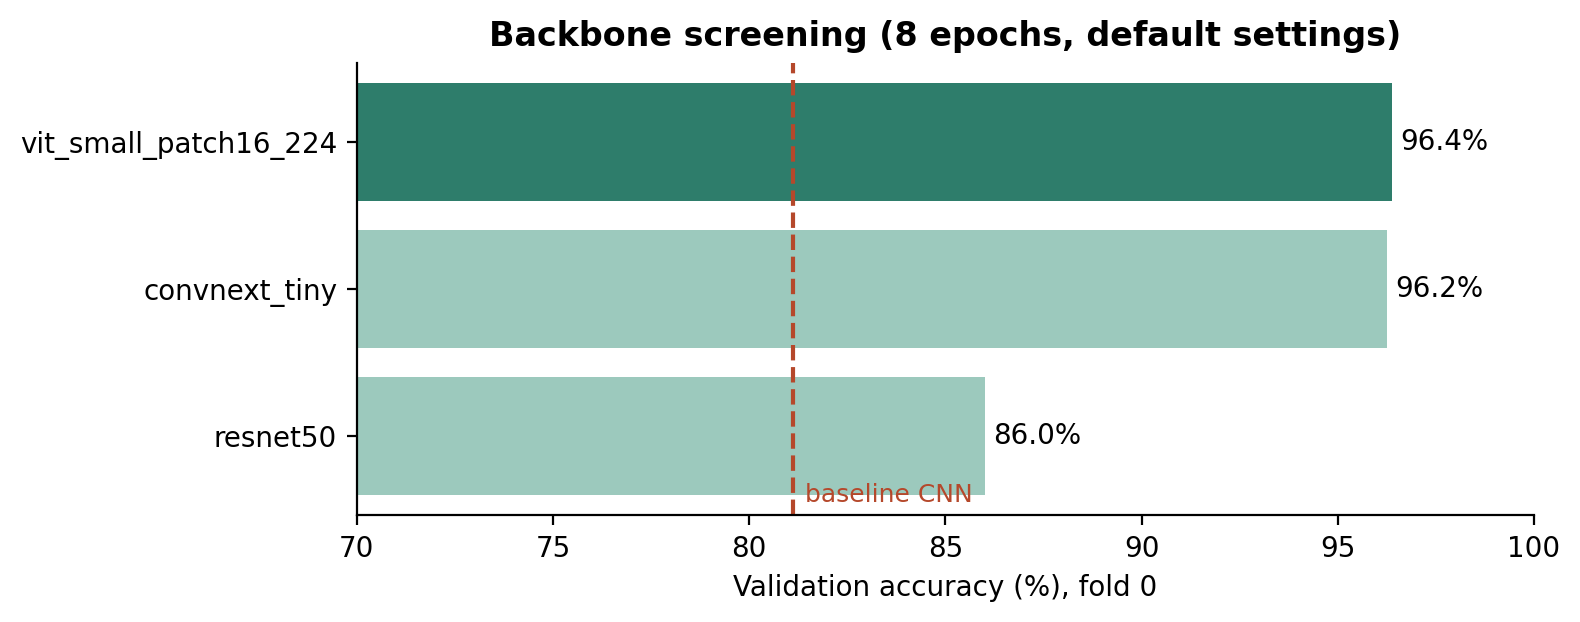

In [7]:
display(table("03_backbone_screening"))
show("03_backbone_screening", 750)

ViT-Small (96.4%) and ConvNeXt-Tiny (96.3%) are **far above the baseline** and tied within one image. ResNet-50 (86.0%) is behind: it was pretrained on ImageNet-1k (1.3M images), while the other two used ImageNet-21k/22k (≈14M images). **ViT-Small** was selected for tuning: highest score, smallest (21.7M parameters) and fastest.

## 5 · Requirement 3: hyper-parameter selection with Bayesian optimisation
### Algorithm
- **Why not grid search?** Seven hyper-parameters with just 4 values each would need 4⁷ = 16,384 training runs.
- **Why not random search?** It spends many trials in obviously poor regions.

The search used **Optuna** with:
1. **TPE sampler** (Tree-structured Parzen Estimator; Bergstra et al., 2011), a **Bayesian optimisation** method.
   - After 6 random start-up trials, TPE splits finished trials into a *good* group (top scores) and a *bad* group.
   - It fits a probability density to the hyper-parameter values in each group, *l(x)* for good and *g(x)* for bad.
   - It proposes the candidate that maximises **l(x)/g(x)**: settings that look like past good trials and unlike bad ones.
   - Each result updates the densities, so the search **learns where to look**.
2. **Median pruner.** After each epoch, a trial is stopped if its validation accuracy is below the **median** of earlier trials at the same epoch. The first 5 trials and the first 3 epochs of every trial are never pruned. This cuts the cost of bad trials roughly in half.

**Objective:** maximise validation accuracy on fold 0 (ViT-Small, 10 epochs per trial). The study is stored in SQLite, so it can be resumed.

```python
def objective(trial):
    params = {
        "lr":                trial.suggest_float("lr", 2e-5, 5e-4, log=True),
        "weight_decay":      trial.suggest_float("weight_decay", 1e-3, 0.2, log=True),
        "label_smoothing":   trial.suggest_float("label_smoothing", 0.0, 0.2),
        "randaug_magnitude": trial.suggest_int("randaug_magnitude", 0, 15),
        "erase_prob":        trial.suggest_float("erase_prob", 0.0, 0.5),
        "drop_path_rate":    trial.suggest_float("drop_path_rate", 0.0, 0.3),
        "warmup_epochs":     trial.suggest_int("warmup_epochs", 0, 2),
    }
    ...  # build loaders + model, train; after every epoch: trial.report(val_acc, epoch); prune if trial.should_prune()
    return best_val_acc

study = optuna.create_study(direction="maximize",
                            sampler=optuna.samplers.TPESampler(seed=42, n_startup_trials=6),
                            pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=3))
study.optimize(objective, n_trials=20, timeout=45 * 60)
```

### Results
**20 trials in 34 minutes** (10 completed, 10 pruned). Best trial: **98.1%** on fold 0, versus 96.4% with default settings, so the validation error was nearly halved.

,number,value,state,drop_path_rate,erase_prob,label_smoothing,lr,randaug_magnitude,warmup_epochs,weight_decay,duration_min
0,19,0.98125,COMPLETE,0.00148,0.21249,0.19615,0.00009,8,0,0.09312,2.19290
1,11,0.97500,COMPLETE,0.02921,0.01830,0.12423,0.00003,10,1,0.02264,2.14664
2,0,0.97375,COMPLETE,0.04680,0.07801,0.14640,0.00007,9,0,0.15404,2.30558
3,15,0.97375,COMPLETE,0.04635,0.00335,0.16772,0.00004,6,1,0.03764,2.19503
4,16,0.97375,COMPLETE,0.01853,0.03459,0.06767,0.00007,8,0,0.11559,2.20417
5,3,0.97125,COMPLETE,0.05990,0.39259,0.07327,0.00003,7,1,0.00470,2.20966
6,9,0.97000,COMPLETE,0.02174,0.10682,0.19745,0.00011,11,1,0.02266,2.19245
7,2,0.97000,COMPLETE,0.08737,0.21597,0.06085,0.00004,8,1,0.00264,2.20884


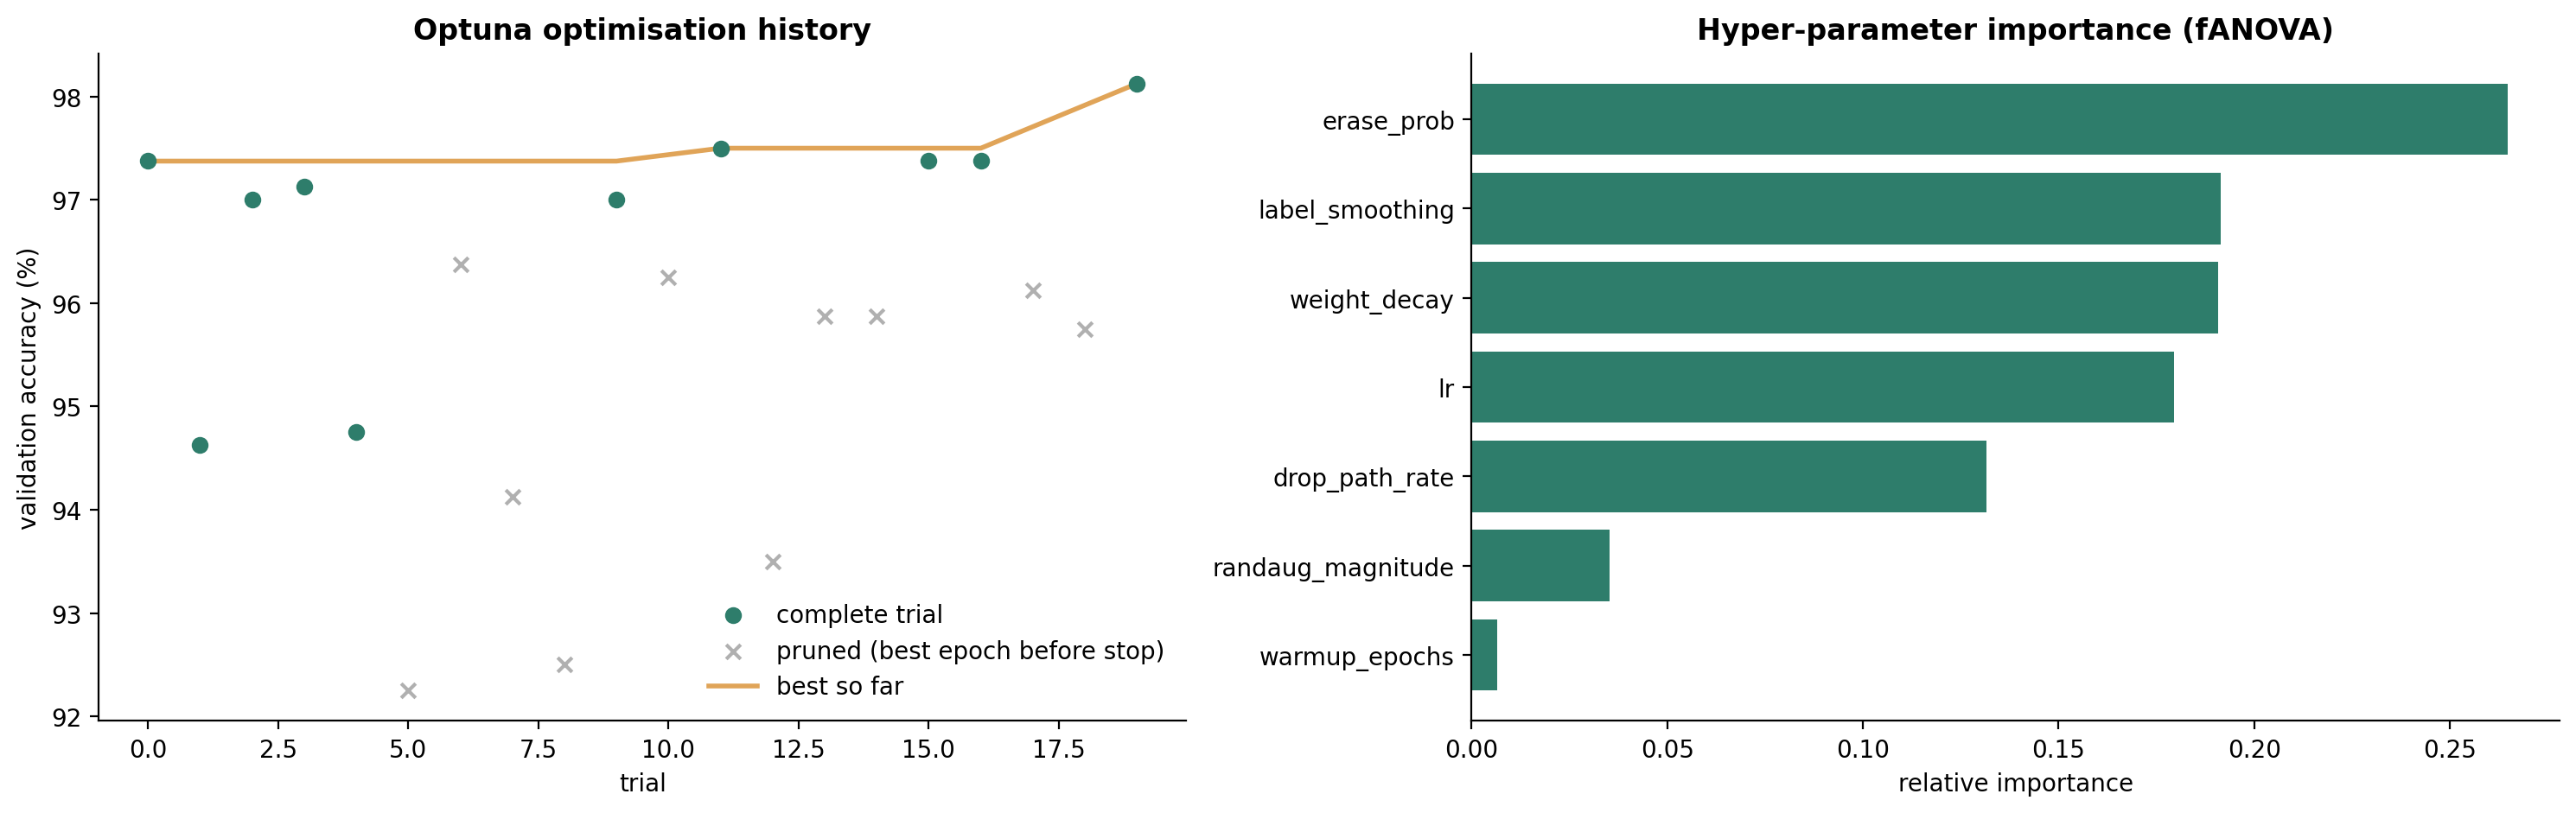

In [8]:
trials = table("03_optuna_trials")
display(trials.head(8))
show("03_optuna_history_importance", 1000)

In [9]:
with open(os.path.join(PATHS["processed"], "best_params.json")) as f:
    best = json.load(f)
pd.Series(best, name="selected value").to_frame()

,selected value
backbone,vit_small_patch16_224.augreg_in21k_ft_in1k
img_size,224
batch_size,64
search_epochs,10
val_acc_fold0,0.9812
lr,0.000092
weight_decay,0.093117
label_smoothing,0.196151
randaug_magnitude,8
erase_prob,0.212491


**What the search found:**
- **Strong regularisation works best:** label smoothing ≈ 0.20, weight decay ≈ 0.09, moderate RandAugment (8) and random erasing (0.21). That suits a small training set.
- **Little or no drop-path, and no warm-up.** Learning rate ≈ 9e-5 is a typical fine-tuning rate; rates of 1.5e-4 or more scored lower.
- **The two worst completed trials** combined high drop-path (≈0.25–0.28) with almost no RandAugment.
- **Importance (fANOVA):** erase probability, label smoothing, weight decay and learning rate mattered most; warm-up barely mattered. With 10 completed trials these are indications only.

The 98.1% is **optimistically biased**: it is the best of 20 scores on the same 800 images. The unbiased accuracy is measured next.

## 6 · Requirement 4: final training and honest accuracy (notebook 04)
### Method
- **5-fold cross-validation.** For each fold *k*, a model is trained on the other 4 folds (3,200 images) and predicts fold *k*. Every labelled image is thus predicted once by a model that never saw it. The **out-of-fold (OOF) accuracy over all 4,000 images** is a fair estimate of test accuracy.
- **Last-epoch weights** are used, not the best epoch, so the validation fold is not used to pick the weights.
- **Two architectures:**
  - ViT-Small with the tuned settings.
  - ConvNeXt-Tiny with the same settings (not separately tuned).

  They are combined by **averaging predicted probabilities**. The ensemble was kept because its OOF accuracy beats both single models.
- **Test-time augmentation (TTA):** each image is predicted as-is and mirrored, and the two probability vectors are averaged.
- **Test prediction:** average of the **10 fold models** (5 per architecture), each with TTA.

,fold,convnext_tiny,vit_small
0,0,0.9725,0.9762
1,1,0.9800,0.9725
2,2,0.9750,0.9738
3,3,0.9712,0.9750
4,4,0.9750,0.9825


,model,OOF accuracy,fold std
0,vit_small,0.9760,0.0039
1,convnext_tiny,0.9748,0.0034
2,ensemble (mean),0.9805,NaN


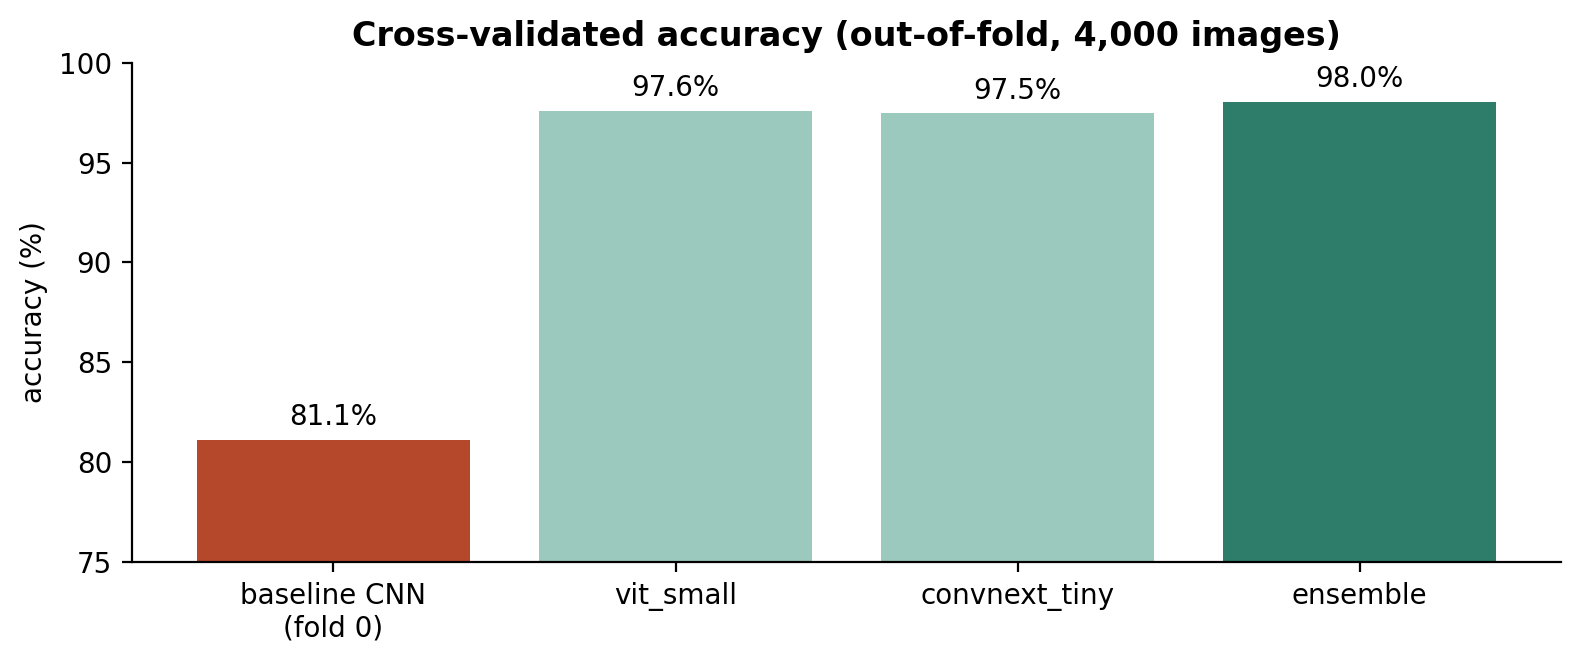

In [10]:
display(table("04_per_fold_accuracy"))
display(table("04_cv_summary"))
show("04_cv_accuracy", 800)

- **ViT-Small 97.60%, ConvNeXt-Tiny 97.48%, ensemble 98.05%** (78 errors out of 4,000).
- Per-fold accuracy ranges from 97.1% to 98.3% (std ≈ 0.4 points), so the result is **stable** across splits.
- The single-model 97.6% is slightly below the 98.1% found during the search, confirming the expected selection bias.
- Averaging two different architectures removed about **18% of the remaining errors** (2.40% → 1.95%).

## 7 · Error analysis

,class,precision,recall,f1-score,support
0,airplane,0.978,0.982,0.980,400.00
1,automobile,0.982,0.968,0.975,400.00
2,bird,0.983,0.985,0.984,400.00
3,cat,0.977,0.952,0.965,400.00
4,deer,0.995,0.980,0.987,400.00
5,dog,0.965,0.970,0.968,400.00
6,frog,0.985,0.998,0.991,400.00
7,horse,0.983,0.995,0.989,400.00
8,ship,0.988,0.988,0.988,400.00
9,truck,0.971,0.988,0.979,400.00


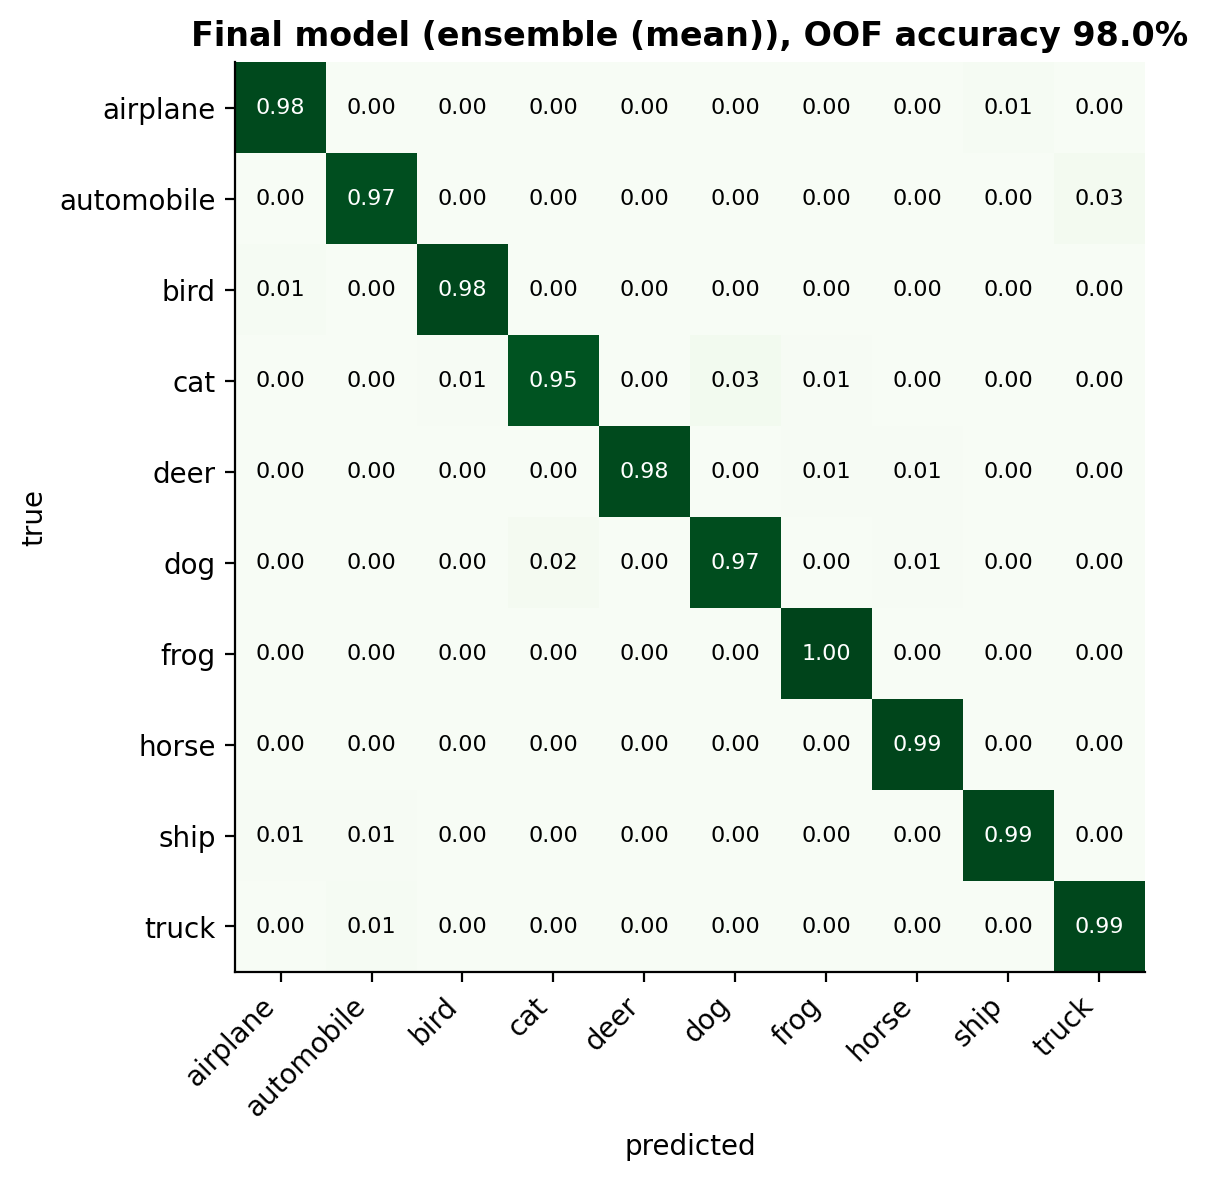

In [11]:
display(table("04_classification_report"))
show("04_confusion_matrix", 600)

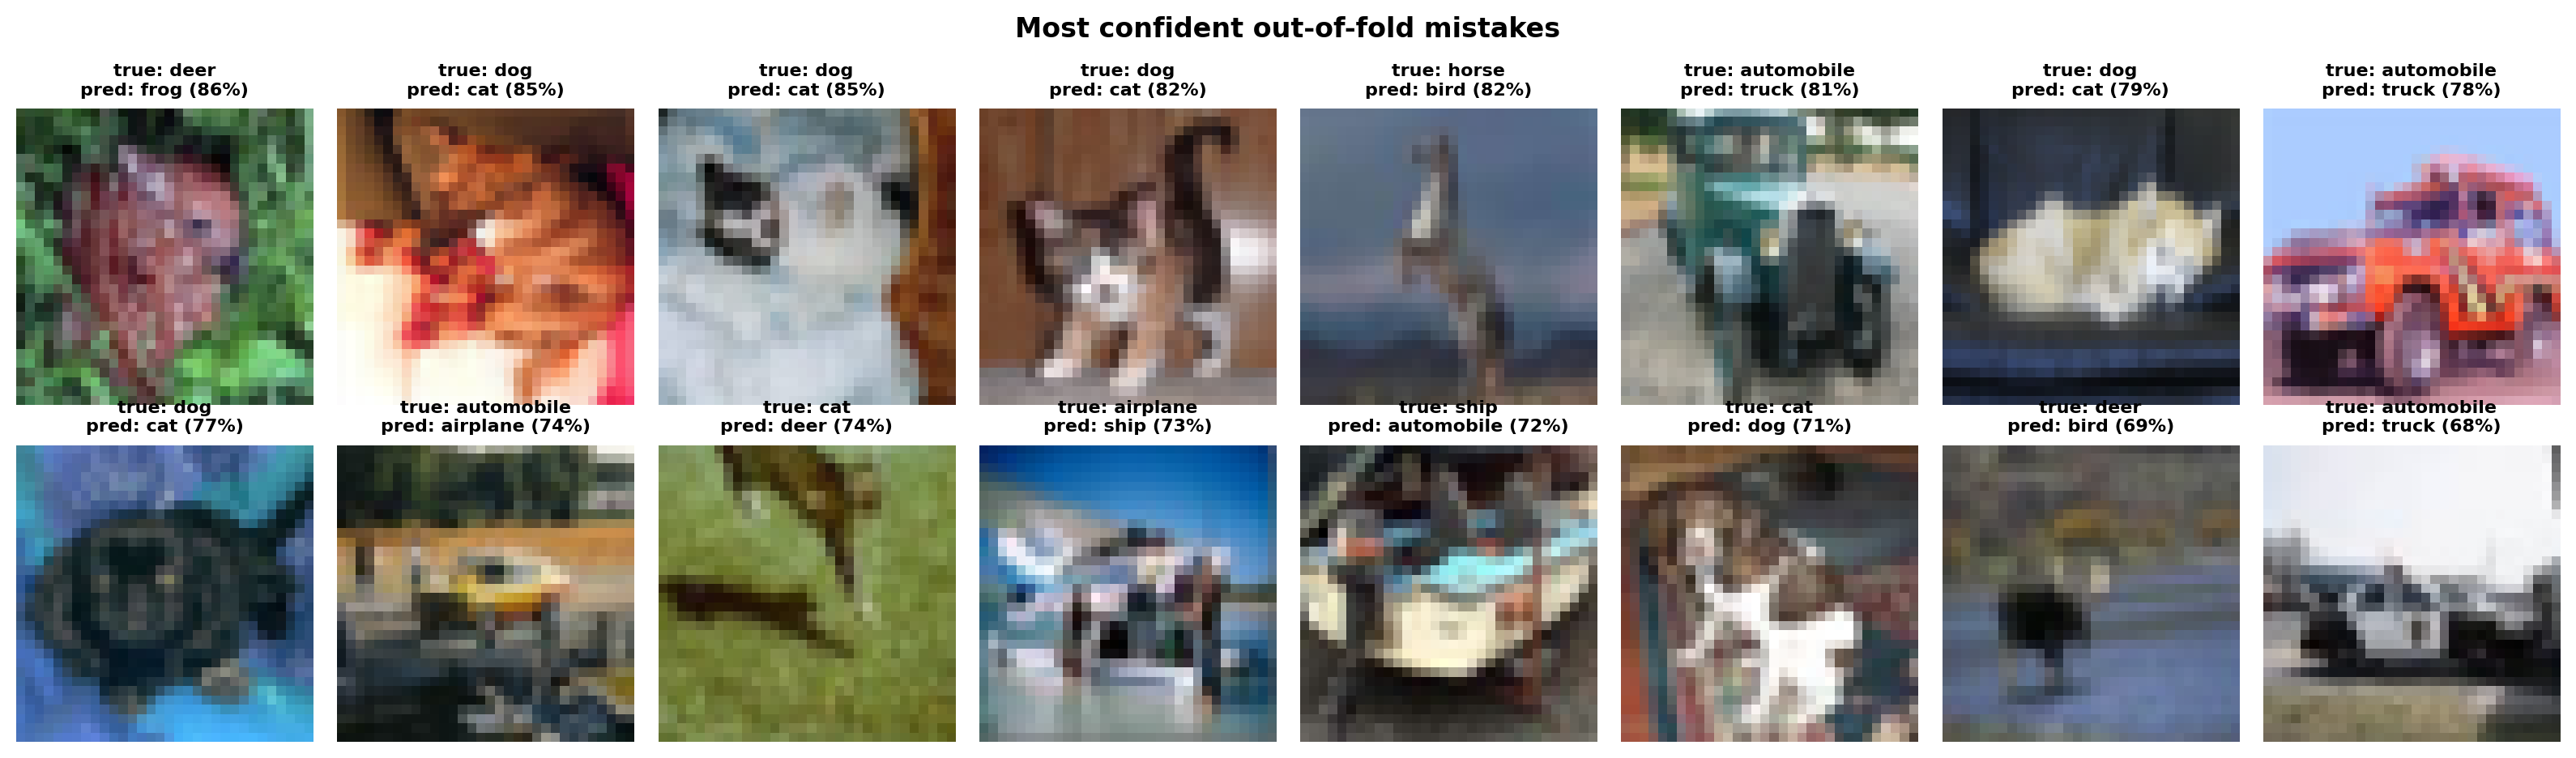

In [12]:
show("04_confident_mistakes", 1100)

- **All classes reach at least 95% recall.** Cat is hardest (95.2%, up from 60% in the baseline), followed by automobile (96.8%) and dog (97.0%).
- **Remaining confusions are semantically close pairs:** cat↔dog and automobile→truck (jeep- and pick-up-like cars).
- **The most confident mistakes are mostly genuinely hard images:** tiny or distant objects, unusual viewpoints, and a few "dog" images that look like cats even to a human at 32×32. This suggests a small amount of label noise or ambiguity that limits further gains.
- **The training curves** (notebook 04) show validation accuracy and loss stable until the last epoch. There is no harmful overfitting, unlike the baseline.

## 8 · The submission file: checks and export
The predictions were produced in notebook 04. Here the file is **re-verified** against `Test.csv` and exported as `Test_predictions.csv`.

In [13]:
sub = pd.read_csv(os.path.join(PATHS["submission"], "submission.csv"))
test_csv = pd.read_csv(DATA_DIR / "Test.csv")
probs = np.load(os.path.join(PATHS["processed"], "test_probs_ensemble.npy"))
checks = {
    "same columns as Test.csv (id, label)": list(sub.columns) == list(test_csv.columns),
    "same number of rows (46,000)": len(sub) == len(test_csv),
    "same ids in the same order": bool((sub["id"].values == test_csv["id"].values).all()),
    "no duplicate ids": not sub["id"].duplicated().any(),
    "no missing labels": bool(sub["label"].notna().all()),
    "every label is one of the 10 class names": bool(sub["label"].isin(cu.CLASSES).all()),
    "labels match the saved ensemble probabilities": bool((np.array(cu.CLASSES)[probs.argmax(1)] == sub["label"].values).all()),
    "no test image was used as a training image": not set(sub["id"]) & set(train_df["id"]),
}
check_df = pd.DataFrame({"check": checks.keys(), "passed": checks.values()})
cu.save_table(check_df, "05_submission_checks", NOTEBOOK, caption="Validation of the submission file against Test.csv.")
assert check_df["passed"].all(), "a submission check failed"
check_df

Table saved  -> /content/drive/MyDrive/DSA4050/cat2-image-classification/outputs/tables/05_submission_checks.csv


,check,passed
0,"same columns as Test.csv (id, label)",True
1,"same number of rows (46,000)",True
2,same ids in the same order,True
3,no duplicate ids,True
4,no missing labels,True
5,every label is one of the 10 class names,True
6,labels match the saved ensemble probabilities,True
7,no test image was used as a training image,True


Saved: /content/drive/MyDrive/DSA4050/cat2-image-classification/outputs/submission/Test_predictions.csv (46000, 2)
Figure saved -> /content/drive/MyDrive/DSA4050/cat2-image-classification/outputs/figures/05_test_class_distribution.png


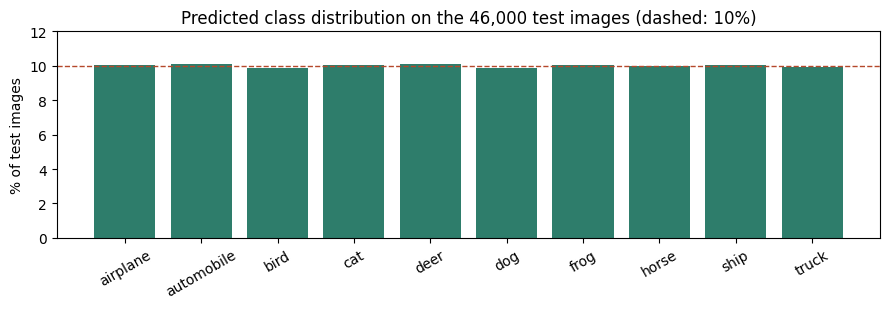

,id,label
0,33680,truck
1,24631,deer
2,34739,dog
3,15922,truck
4,44282,automobile
5,7754,cat
6,44017,horse
7,25147,frog
8,8224,cat
9,8068,cat


In [14]:
out = test_csv[["id"]].copy()
out["label"] = sub["label"].values                        # Test.csv with the label column filled
final_path = os.path.join(PATHS["submission"], "Test_predictions.csv")
out.to_csv(final_path, index=False)
print("Saved:", final_path, out.shape)

fig, ax = plt.subplots(figsize=(9, 3.2))
share = out["label"].value_counts(normalize=True).reindex(cu.CLASSES) * 100
ax.bar(cu.CLASSES, share, color="#2E7D6B"); ax.axhline(10, color="#B5482B", ls="--", lw=1)
ax.set_ylabel("% of test images"); ax.set_ylim(0, 12); ax.tick_params(axis="x", rotation=30)
ax.set_title("Predicted class distribution on the 46,000 test images (dashed: 10%)")
fig.tight_layout(); cu.save_figure(fig, "05_test_class_distribution", NOTEBOOK, caption="Share of each predicted class in the test set.")
plt.show()
out.head(10)

In [15]:
# Agreement between the two architectures on the test images
fold_dir = os.path.join(PATHS["models"], "folds")
p_vit = np.mean([np.load(f) for f in sorted(glob.glob(os.path.join(fold_dir, "vit_small_fold*_test.npy")))], axis=0)
p_cnx = np.mean([np.load(f) for f in sorted(glob.glob(os.path.join(fold_dir, "convnext_tiny_fold*_test.npy")))], axis=0)
agree = (p_vit.argmax(1) == p_cnx.argmax(1)).mean()
cu.log_result("test_agreement_vit_convnext", round(float(agree), 4), NOTEBOOK)
print(f"ViT and ConvNeXt agree on {agree:.1%} of the {len(out):,} test images "
      f"({int(round((1 - agree) * len(out))):,} disagreements, settled by averaging their probabilities).")

Result logged: test_agreement_vit_convnext = 0.9813
ViT and ConvNeXt agree on 98.1% of the 46,000 test images (860 disagreements, settled by averaging their probabilities).


### Visual check of the test predictions
The test images have no labels, so their predictions cannot be scored. Instead they can be **checked by eye**:
1. **8 random test images for each predicted class.** Each row should contain only that class.
2. **The 16 least confident test predictions.** These are where mistakes are most likely.

Figure saved -> /content/drive/MyDrive/DSA4050/cat2-image-classification/outputs/figures/05_test_predictions_by_class.png


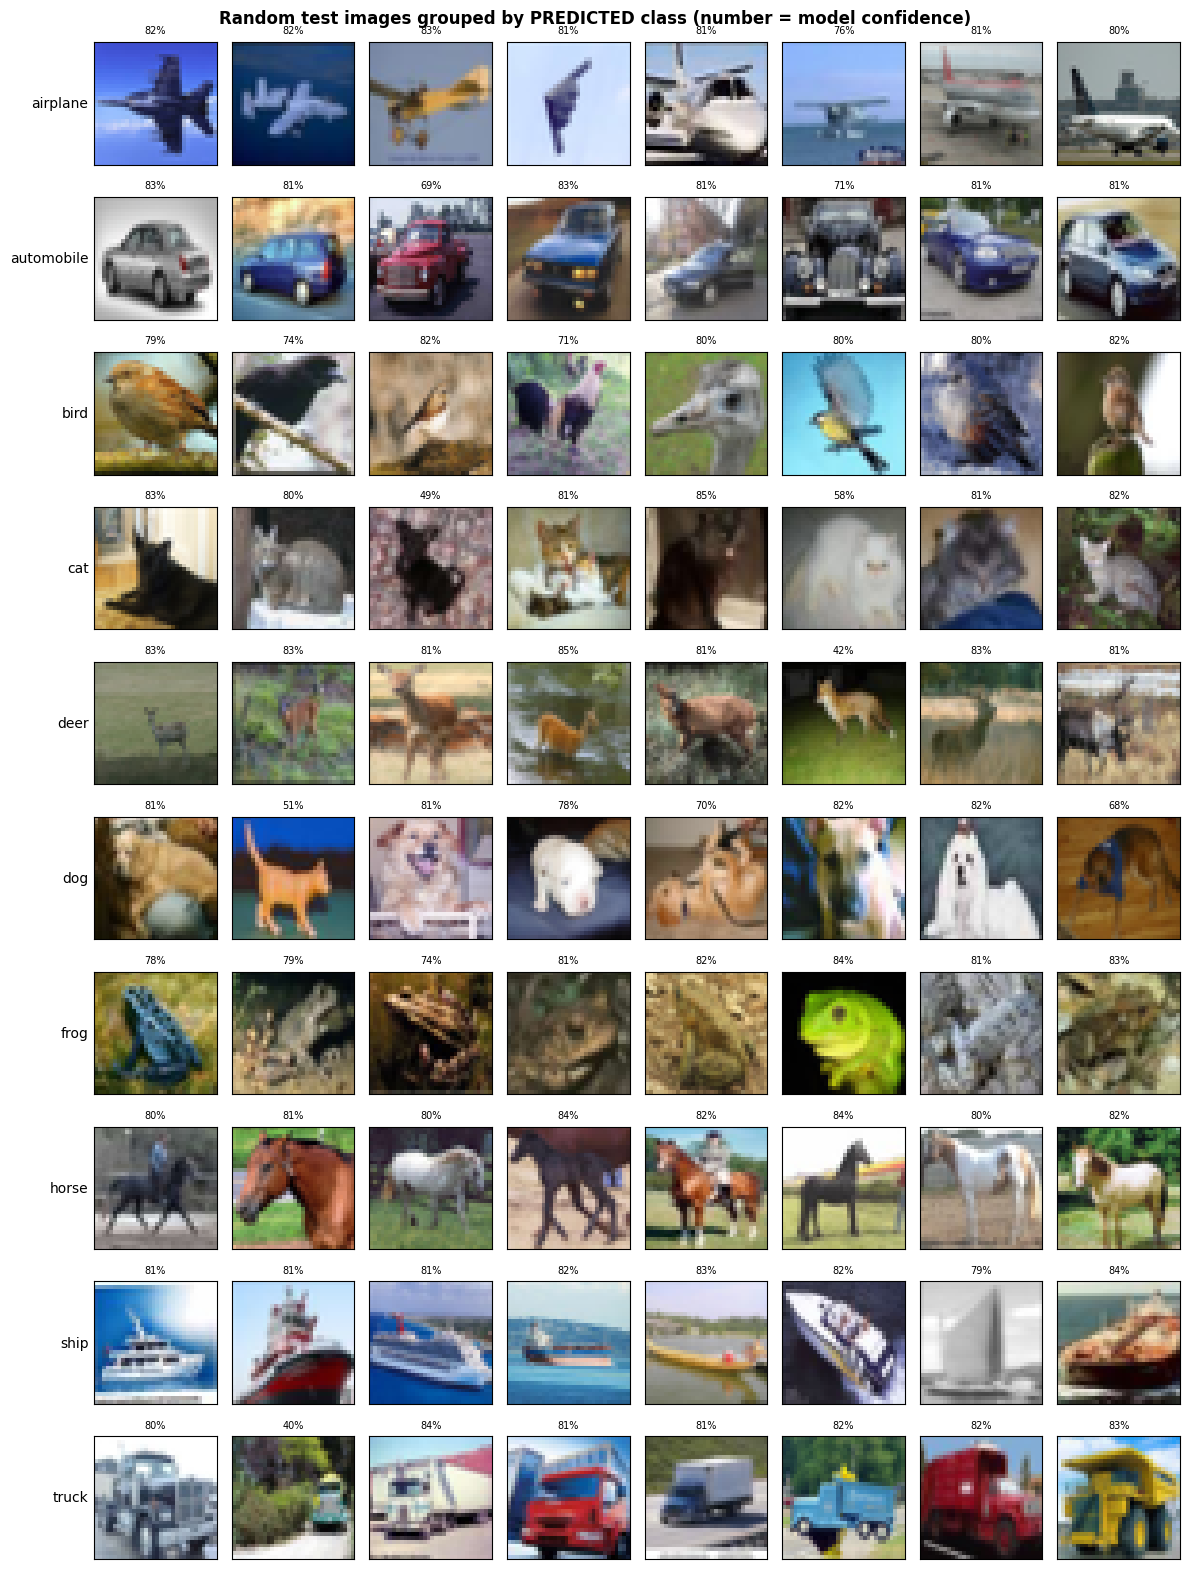

In [16]:
X_test_cache = DATA_DIR / "test_images.npy"
X_test = np.load(X_test_cache) if X_test_cache.exists() else cu.load_images(out["id"], DATA_DIR / "train")
pred_idx, conf = probs.argmax(1), probs.max(1)
rng = np.random.default_rng(cu.SEED)

fig, axes = plt.subplots(10, 8, figsize=(12, 16))
for r, cls in enumerate(cu.CLASSES):
    pool = np.where(pred_idx == r)[0]
    for ax, i in zip(axes[r], rng.choice(pool, size=min(8, len(pool)), replace=False)):
        ax.imshow(X_test[i], interpolation="nearest"); ax.set_title(f"{conf[i]:.0%}", fontsize=7)
    for ax in axes[r]:
        ax.set_xticks([]); ax.set_yticks([])
    axes[r][0].set_ylabel(cls, fontsize=10, rotation=0, ha="right", va="center")
fig.suptitle("Random test images grouped by PREDICTED class (number = model confidence)", fontweight="bold")
fig.tight_layout()
cu.save_figure(fig, "05_test_predictions_by_class", NOTEBOOK, caption="Random test images for each predicted class.")
plt.show()

Figure saved -> /content/drive/MyDrive/DSA4050/cat2-image-classification/outputs/figures/05_test_least_confident.png


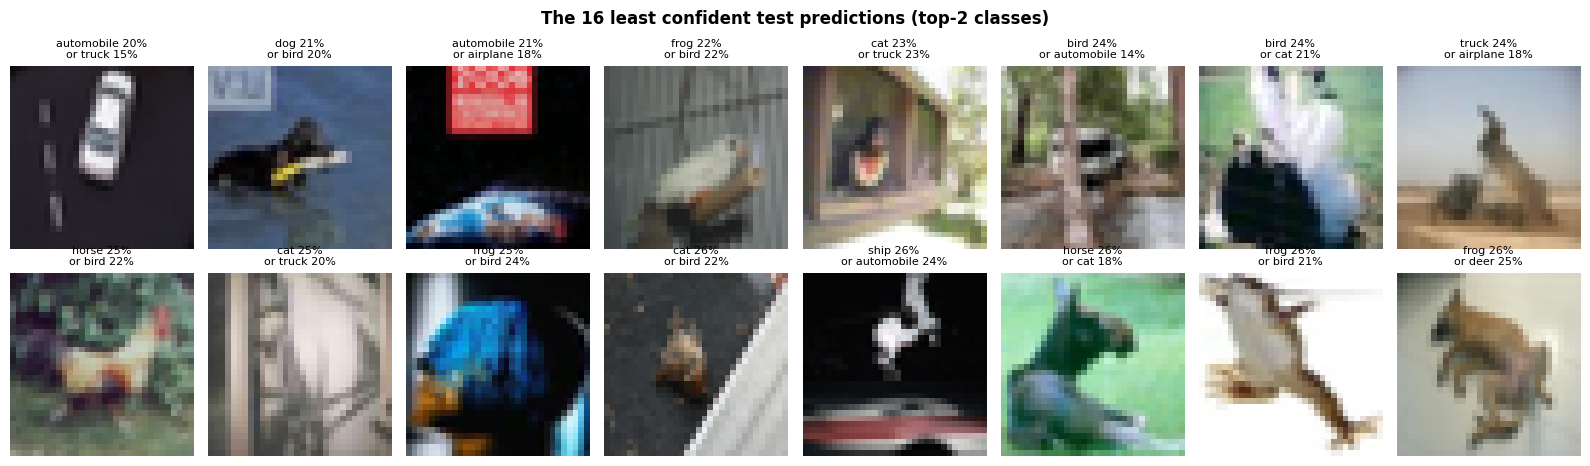

In [17]:
low = np.argsort(conf)[:16]
top2 = np.argsort(-probs[low], axis=1)[:, :2]
fig, axes = plt.subplots(2, 8, figsize=(16, 4.8))
for ax, i, (a, b) in zip(axes.flat, low, top2):
    ax.imshow(X_test[i], interpolation="nearest"); ax.axis("off")
    ax.set_title(f"{cu.CLASSES[a]} {probs[i, a]:.0%}\nor {cu.CLASSES[b]} {probs[i, b]:.0%}", fontsize=8)
fig.suptitle("The 16 least confident test predictions (top-2 classes)", fontweight="bold")
fig.tight_layout()
cu.save_figure(fig, "05_test_least_confident", NOTEBOOK, caption="Test images with the least confident predictions.")
plt.show()

**Interpretation:**
- **By-class grid:** almost every image sits in the correct row: jets and airliners, saloon cars, birds of many species, frogs, horses (with and without riders), ships and lorries.
  - **One clear mistake:** an orange cat in the *dog* row.
  - **A few doubtful cases:** a dark animal in the *cat* row, a fox-like animal in the *deer* row, and a small vehicle half-hidden by bushes in the *truck* row.
  - About 1–3 doubtful images out of 80 is in line with the expected ≈2% error rate.
  - **The doubtful images are exactly the ones with low confidence (40–58%),** while correct ones sit at about 80% (the ceiling set by label smoothing). Confidence is therefore a useful warning signal.
- **Least confident predictions:** these are genuinely hard images, not systematic failures. They include a car seen from directly above, a cat behind a window, a leaping animal against a white background, a close-up of a bird's head, and heavily cropped or dark scenes. The top probability is only 20–26%, so the models are unsure and spread probability over several classes. In several cases the plausible true class (e.g. bird for the rooster) is the second guess.
- **Agreement:** ViT and ConvNeXt agree on **98.1%** of the 46,000 test images. Only 860 images (1.9%) needed the averaged probabilities to settle a disagreement. That is consistent with the cross-validated result, where the ensemble corrected about 18% of the single models' errors.

- The predicted classes are **almost exactly 10% each** (9.9–10.1%). That matches the balanced training data and shows the model is not biased toward any class.
- The two architectures agree on the large majority of test images. Where they disagree, the averaged probabilities decide, which is where the ensemble gains its extra accuracy.

## 9 · Reproducibility and integrity
- **Run order:** `00_project_setup` → `01_data_exploration` → `02_baseline_cnn` → `03_hyperparameter_search` → `04_final_training` → `05_submission_and_report` (Google Colab, T4 GPU).
  - GPU time: about 6 min for 02, 50 min for 03, 50 min for 04.
  - Every long step saves progress to Google Drive and resumes after a disconnect.
- **Seeds** are fixed (42; 42+k for fold *k*). GPU training is not bit-for-bit deterministic, so re-runs can differ by a few images.
- **Logs:** every experiment is logged in `outputs/experiments.csv`, key numbers in `outputs/results.json`, and all figures and tables in `outputs/`.
- **Data integrity:**
  - The only labels used are the 4,000 in `Train.csv`. No external copy of the dataset or its labels was used.
  - The only outside knowledge is the publicly available **ImageNet-pretrained weights** (via `timm`), which is standard transfer learning.
  - The test images were used only for prediction: no pseudo-labelling or other training on them.
- **Environment:** Python 3.13, PyTorch 2.11, torchvision 0.26, timm 1.0, Optuna 5.0, scikit-learn 1.6.

In [18]:
pd.read_csv(cu.EXPERIMENTS_FILE)

,model,val_acc_fold0,train_acc_last,train_minutes,params_millions,img_size,params,notes,notebook,saved_at,oof_acc_5fold
0,baseline_cnn_scratch,0.8113,0.9628,5.7,2.78,32,"{""epochs"": 100, ""lr"": 0.1, ""optimizer"": ""sgd"",...",NaN,02_baseline_cnn,2026-11-05 16:27:10,NaN
1,screen_resnet50,0.8600,NaN,2.1,23.50,224,"{""epochs"": 8, ""lr"": 0.0001, ""wd"": 0.05, ""randa...",NaN,03_hyperparameter_search,2026-11-05 17:12:23,NaN
2,screen_convnext_tiny,0.9625,NaN,2.5,27.80,224,"{""epochs"": 8, ""lr"": 0.0001, ""wd"": 0.05, ""randa...",NaN,03_hyperparameter_search,2026-11-05 17:14:55,NaN
3,screen_vit_small_patch16_224,0.9637,NaN,1.8,21.70,224,"{""epochs"": 8, ""lr"": 0.0001, ""wd"": 0.05, ""randa...",NaN,03_hyperparameter_search,2026-11-05 17:16:48,NaN
4,optuna_best_vit_small_patch16_224,0.9812,NaN,NaN,NaN,224,"{""lr"": 9.228492857640522e-05, ""weight_decay"": ...",best of 20 Optuna trials,03_hyperparameter_search,2026-11-05 17:52:36,NaN
5,final_5fold_vit_small,NaN,NaN,NaN,NaN,224,"{""epochs"": 10, ""tta"": ""hflip""}","5-fold CV, last-epoch weights",04_final_training,2026-11-05 19:02:31,0.9760
6,final_5fold_convnext_tiny,NaN,NaN,NaN,NaN,224,"{""epochs"": 10, ""tta"": ""hflip""}","5-fold CV, last-epoch weights",04_final_training,2026-11-05 19:02:32,0.9748
7,final_5fold_ensemble,NaN,NaN,NaN,NaN,224,"{""epochs"": 10, ""tta"": ""hflip""}","5-fold CV, last-epoch weights",04_final_training,2026-11-05 19:02:32,0.9805


## 10 · Conclusions
1. **Transfer learning is decisive in this low-data setting.** Fine-tuning ImageNet-21k-pretrained networks raised accuracy from 81.1% (from scratch) to about 96% with default settings.
2. **Bayesian hyper-parameter optimisation** (Optuna TPE + median pruning) found a better configuration in 34 minutes (20 trials, half pruned). It showed that strong regularisation (label smoothing, weight decay, random erasing) matters most when data is scarce.
3. **Cross-validation** gave an honest accuracy estimate and exposed the small optimistic bias of the tuning score.
4. **An ensemble of two architectures with TTA** reached **98.05% cross-validated accuracy**. That is the expected accuracy on the 46,000 test images.
5. **Possible further gains:**
   - Pseudo-labelling the confident test predictions to enlarge the training set.
   - Larger backbones or higher resolution.
   - Tuning ConvNeXt separately.

   The remaining errors are largely ambiguous images, so further gains would be small.

### References
- Bergstra, J., Bardenet, R., Bengio, Y., & Kégl, B. (2011). *Algorithms for hyper-parameter optimization.* NeurIPS.
- Akiba, T., Sano, S., Yanase, T., Ohta, T., & Koyama, M. (2019). *Optuna: A next-generation hyperparameter optimization framework.* KDD.
- Dosovitskiy, A., et al. (2021). *An image is worth 16×16 words: Transformers for image recognition at scale.* ICLR.
- Liu, Z., et al. (2022). *A ConvNet for the 2020s.* CVPR.
- Cubuk, E. D., Zoph, B., Shlens, J., & Le, Q. V. (2020). *RandAugment: Practical automated data augmentation with a reduced search space.* CVPR Workshops.
- Zhong, Z., Zheng, L., Kang, G., Li, S., & Yang, Y. (2020). *Random erasing data augmentation.* AAAI.
- He, K., Zhang, X., Ren, S., & Sun, J. (2016). *Deep residual learning for image recognition.* CVPR.
- Wightman, R. (2019). *PyTorch Image Models (timm).* GitHub.

In [19]:
cu.project_summary()

Project root : /content/drive/MyDrive/DSA4050/cat2-image-classification
Figures      : 17
Tables       : 12
Models       : 1
Results      : 31
Experiments  : 8
